## Modeling Problem Definition

The objective is formulated as a supervised regression problem in which each observation represents one player-season. Player characteristics, season performance, club context and historical information are used to estimate the player's end-of-season market value.

The log-transformed market value is used as the modeling target due to the strong right-skew observed during EDA and the large differences in scale between players. Predictions will later be transformed back to euros for interpretation and evaluation.

Two modeling scenarios will be evaluated: one excluding historical market value and another including it. This distinction is important because previous market value showed an extremely strong relationship with the target (`see 01_eda_modeling_dataset.ipynb`). Comparing both scenarios will allow the analysis to distinguish the predictive contribution of football-related features from the persistence already contained in historical valuations.

### 1. Setup and Imports

In [1]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

In [2]:
# import dataset
df = pd.read_csv("../data/processed/modeling_dataset_v1.csv")

In [3]:
# create log cols (see 01_eda_modeling_dataset.ipynb for reference)

    # market value
df["log_target_market_value"] = np.log1p(
    df["target_market_value_in_eur"]
)

    # previous market value
df["log_previous_market_value"] = np.log1p(
    df["previous_market_value_in_eur"]
)

### 2. Temporal Validation Strategy

The dataset contains repeated observations of players across multiple seasons, and the intended use case is to estimate market values for a new season using information learned from previous seasons. Therefore, a random train-test split would not realistically represent deployment.

That is why it was decided to go with an expanding-window temporal validation strategy. Each validation season is predicted using only seasons that occurred before it, while the training window grows as more historical data becomes available.

The 2025 season is excluded from all model development and reserved as the final test set. This provides an unbiased evaluation of the final selected modeling approach on the most recent unseen season.

This approach is particularly relevant because football market values show strong persistence between seasons. Model performance will therefore also be compared against a simple historical-value baseline to determine whether the additional player, performance and contextual features improve upon simply carrying forward the previous valuation.

In [4]:
# Create dev df (2020-2024) and test df (2025)
dev_df = df[df["season"]<=2024].copy()
test_df = df[df["season"]==2025].copy()

print(f"Development df observations: {len(dev_df)}")
print(f"Testing df observations: {len(test_df)}")


Development df observations: 12898
Testing df observations: 2459


In [5]:
# AI-assisted implementation:
# The expanding-window fold construction below was developed with support from ChatGPT
# (OpenAI, 2026) to preserve chronological order and avoid future-data leakage.

# Create folds for each development season
validation_seasons = [2021, 2022, 2023, 2024]

temporal_folds = []

for validation_season in validation_seasons:
    train = dev_df[dev_df["season"] < validation_season].copy()

    validation = dev_df[dev_df["season"] == validation_season].copy()

    temporal_folds.append({
        "validation_season": validation_season,
        "train" : train,
        "validation": validation
    }) 

In [6]:
# Generate fold summary to check correct creation
fold_summary = []

for fold in temporal_folds:
    fold_summary.append({
        "validation_season": fold["validation_season"],
        "training_seasons": (
            f"{fold['train']['season'].min()}-"
            f"{fold['train']['season'].max()}"
        ),
        "train_rows": len(fold["train"]),
        "validation_rows": len(fold["validation"])
    })

pd.DataFrame(fold_summary)

,validation_season,training_seasons,train_rows,validation_rows
0,2021,2020-2020,2617,2485
1,2022,2020-2021,5102,2657
2,2023,2020-2022,7759,2650
3,2024,2020-2023,10409,2489


### 3. Feature Definition

The candidate modeling features are defined based on the findings from `01_eda_modeling_dataset.ipynb`, considering always the information that is available before the end-of-season valuations.

Identifiers are excluded; the retained features represent player characteristics, season performance, club context, and transfer history.

As explained above, we will create two sets. One will have the historical market values, and the other won't have that information. As seen in the EDA notebook referenced above, this is to evaluate separately the predictive contribution of football-related statistics from the strong persistence we observed in historical valuations.

#### 3.1 Target Variable

In [7]:
# Define the target variable
target_variable = "log_target_market_value"

#### 3.2 Categorical Features

In [8]:
# Define categorical features
categorical_features = [
    "position",
    "sub_position",
    "foot",
    "competition_id"
]

Excluded `primary_club_id` for now. After inspecting the dataset we can see that certain club IDs tend to be associated with more expensive players (better team - better players). However, we already have club-performance numeric features to represent the club context in a more meaningful way.

#### 3.3. Numerical Features

In [9]:
# Define numerical features
numeric_features = [
    "season",

    "age_at_valuation",
    "height_in_cm",

    "total_games_played_season",
    "total_minutes_played",

    "total_goals",
    "goals_per_90_min",
    "total_assists",
    "assists_per_90_min",
    "goal_contributions_per_90_min",

    "total_yellow_cards",
    "yellow_cards_per_90_min",
    "total_red_cards",
    "red_cards_per_90_min",

    "total_clean_sheets",
    "clean_sheet_rate",

    "clubs_played_for_season",
    "club_goals_scored",
    "club_goals_conceded",
    "club_games_played",
    "avg_points_per_game",
    
    "total_previous_transfers",
    "transfers_during_season",
    "has_previous_transfer",
    "days_since_last_transfer"
]

Kept aside `wins`, `draws`, `losses` and `points`. As shown in our EDA, wins, points and avg_points_per_game were almost perfectly correlated. Keeping all would be adding too much redundant information.

The metric avg_points_per_game is the cleanest summary of the club results along the season. Also, club_goals_scored and club_goals_conceded add additional context.

#### 3.4. Without Historical Market Value

This model will answer: How well can we estimate market value from the player performance and contextual information alone?

In [10]:
# Join the two lists of features, first without historical market value information
features_without_history = (    
    categorical_features
    + numeric_features
)

#### 3.5. With Historical Market Value

In [11]:
# Define historical features
historical_features = [
    "log_previous_market_value",
    "days_since_previous_valuation"
]

# Join the all the features, now with historical information included
features_with_history = (
    features_without_history +
    historical_features
)

#### 3.6. What was Excluded

##### Reasons for Exclusions

`IDs/name/player_code` -> identifiers

`player_game_participation_rate` -> to remove from model issues with player participation rate when the player had more than one team in a season

`wins/draws/losses/points` -> largely redundant with avg_points_per_game

`previous_market_value_in_eur` -> replaced with the log transformation

`valuation/target columns` -> target information or construction metadata

In [12]:
# Final Checks

print("Features without history:", len(features_without_history))
print("Features with history:", len(features_with_history))

missing_without = [
    col for col in features_without_history
    if col not in df.columns
]

missing_with = [
    col for col in features_with_history
    if col not in df.columns
]

print("Missing without history:", missing_without)
print("Missing with history:", missing_with)

Features without history: 29
Features with history: 31
Missing without history: []
Missing with history: []


### 4. General Preprocessing

Before model training, a common preprocessing strategy is defined for missing values and feature types. Preprocessing parameters are learned only from the training data within each temporal fold to prevent information from future seasons influencing the model.
Model-dependent transformations such as feature scaling and categorical encoding will be defined later according to the requirements of each algorithm.

##### Missing Values

In [13]:
# Generat mising values summary
model_features = list(
    dict.fromkeys(
        features_with_history
    )
)

missing_summary = (
    df[model_features]
    .isna()
    .sum()
    .to_frame("missing_count")
)

missing_summary["missing_pct"] = (
    missing_summary["missing_count"] / len(df) * 100
)

missing_summary = missing_summary[
    missing_summary["missing_count"] > 0
].sort_values("missing_count", ascending=False)

missing_summary

,missing_count,missing_pct
goals_per_90_min,5769,37.565931
assists_per_90_min,5769,37.565931
goal_contributions_per_90_min,5769,37.565931
yellow_cards_per_90_min,5769,37.565931
red_cards_per_90_min,5769,37.565931
clean_sheet_rate,5769,37.565931
days_since_last_transfer,1452,9.454972
log_previous_market_value,82,0.533958
days_since_previous_valuation,82,0.533958
foot,61,0.397213


##### Numeric Values

For missing values in numerical features we will use a SimpleImputer with a median strategy. This is considered better since median is less sensitive to extreme values, as we have in some of our football statistics.

In [14]:
from sklearn.impute import SimpleImputer
# Create numeric imputer
numeric_imputer = SimpleImputer(
    strategy = 'median',
    add_indicator=True
)

##### Categorical Values

Since categorical values missing are few, we will simply add a SimpleImputer with constant strategy, filling the missing value with "missing".

In [15]:
categorical_imputer = SimpleImputer( 
    strategy = 'constant',
    fill_value = 'missing'
)

### 5. Model Specific Preprocessing

Three regression algorithms are evaluated as baselines:

1. `Ridge` provides a regularized linear benchmark.
2. `Random Forest` captures nonlinear relationships through an ensemble of trees.
3. `XGBoost` provides a boosted-tree model suited to nonlinear tabular data. 

All three models are evaluated under the same temporal validation framework.

The untuned version of the best model will then be tuned using GridSearch to find the best parameters.

Each model has different preprocessing needs that will be addressed in the following cells.

#### 5.1. Imports

In [16]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor

from xgboost import XGBRegressor

#### 5.2. Define numerical feature set

In [17]:
# Create two versions, one with and one without historical market value information

numeric_features_without_history = numeric_features.copy()

numeric_features_with_history = (
    numeric_features +
    historical_features
)

print("Numeric features without history:", len(numeric_features_without_history))
print("Numeric features with history:", len(numeric_features_with_history))

Numeric features without history: 25
Numeric features with history: 27


#### 5.3. Categorical Preprocessing

Since our categorical features are relatively small we will use one-hot-encoding for all of them

In [18]:
# Create categorical transformer that applies to the three models
from sklearn.base import clone
categorical_transformer = Pipeline([
    # use categorical imputer for missing values
    (
        "imputer",
        clone(categorical_imputer) 
    ),
    # use onehotencoding for the categories
    (
       "onehotencoder",
       OneHotEncoder(
           handle_unknown="ignore"
       ) 
    )
])

#### 5.4. Numerical Preprocessing - Ridge Regression

Linear regression algorithms don't usually perform well if the numerical attributes have wide ranging values, that is why s StandardScaler is applied for the numeric features

In [19]:
numeric_transformer_linear = Pipeline([
    # use numeric imputer for missing values (median)
    (
        "imputer",
        clone(numeric_imputer)
    ),
    # apply scaling to get numeric features to a comparable scale
    (
        "scaler",
        StandardScaler()
    )
])

#### 5.5. Numerical Preprocessing - Tree Models

Tree models just need the numeric imputer in this case

In [20]:
numeric_transformer_tree = Pipeline([
    # use numeric imputer for missing values (median)
    (
    "imputer",
    clone(numeric_imputer)
    )
])

#### 5.6. Baseline Models

In this section we will give each algorithm a typical starting configuration to see how they behave under the exact same evaluation

##### Ridge Regression

In [21]:
# Ridge Regression baseline model
ridge_model = Ridge(
    alpha=1.0 # regularization strength, 1.0 as starting point
)

##### Random Forest

In [22]:
# Random Forest baseline model
rf_model = RandomForestRegressor(
    n_estimators=300,  # number of decision trees in the forest
    random_state=42,   # makes the model reproducible
    n_jobs=-1          # uses all available CPU cores when training
)


##### XGBoost

In [23]:
# XGBoost baseline
xgb_model = XGBRegressor(
    objective="reg:squarederror",  # regression objective
    n_estimators=300,             # maximum number of boosting trees
    learning_rate=0.05,           # controls how much each new tree contributes
    max_depth=5,                  # maximum depth of each tree
    random_state=42,              # makes the model reproducible
    n_jobs=-1                     # uses all available CPU cores when training
)

#### 5.7. Build baseline pipelines

In [24]:
# Preprocessing for Ridge:
# numerical features are imputed and scaled,
# categorical features are imputed and one-hot encoded.
# without historic valuations
linear_preprocessor_without_history = ColumnTransformer([
    (
        "numeric",
        clone(numeric_transformer_linear),
        numeric_features_without_history
    ),
    (
        "categorical",
        clone(categorical_transformer),
        categorical_features
    )
])

# with historic valuations
linear_preprocessor_with_history = ColumnTransformer([
    (
        "numeric",
        clone(numeric_transformer_linear),
        numeric_features_with_history
    ),
    (
        "categorical",
        clone(categorical_transformer),
        categorical_features
    )
])



# Preprocessing for Random Forest and XGBoost:
# same treatment, but numerical features are not scaled.
# without historic valuations
tree_preprocessor_without_history = ColumnTransformer([
    (
        "numeric",
        clone(numeric_transformer_tree),
        numeric_features_without_history
    ),
    (
        "categorical",
        clone(categorical_transformer),
        categorical_features
    )
])

# with historic valuations
tree_preprocessor_with_history = ColumnTransformer([
    (
        "numeric",
        clone(numeric_transformer_tree),
        numeric_features_with_history
    ),
    (
        "categorical",
        clone(categorical_transformer),
        categorical_features
    )
])

In [25]:
# Without History Pipelines
# Full Ridge pipeline
ridge_pipeline_without_history = Pipeline([
    ("preprocessor", linear_preprocessor_without_history),
    ("model", clone(ridge_model))
])


# Full Random Forest pipeline
rf_pipeline_without_history = Pipeline([
    ("preprocessor", tree_preprocessor_without_history),
    ("model", clone(rf_model))
])


# Full XGBoost pipeline
xgb_pipeline_without_history = Pipeline([
    ("preprocessor", tree_preprocessor_without_history),
    ("model", clone(xgb_model))
])

# With History Pipelines
# Full Ridge pipeline
ridge_pipeline_with_history = Pipeline([
    ("preprocessor", linear_preprocessor_with_history),
    ("model", clone(ridge_model))
])


# Full Random Forest pipeline
rf_pipeline_with_history = Pipeline([
    ("preprocessor", tree_preprocessor_with_history),
    ("model", clone(rf_model))
])


# Full XGBoost pipeline
xgb_pipeline_with_history = Pipeline([
    ("preprocessor", tree_preprocessor_with_history),
    ("model", clone(xgb_model))
])


In [26]:
# Define dicts
baseline_models = {
    "Ridge": ridge_pipeline_without_history,
    "Random Forest": rf_pipeline_without_history,
    "XGBoost": xgb_pipeline_without_history
}

models_with_history = {
    "Ridge": ridge_pipeline_with_history,
    "Random Forest": rf_pipeline_with_history,
    "XGBoost": xgb_pipeline_with_history
}

models_without_history = {
    "Ridge": ridge_pipeline_without_history,
    "Random Forest": rf_pipeline_without_history,
    "XGBoost": xgb_pipeline_without_history
}

### 6. Baseline Walk-Forward Evaluation

In [27]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# baseline results list
baseline_results = []


# Iterate over the models
for model_name, pipeline in models_without_history.items():

    for fold in temporal_folds:
        validation_season = fold["validation_season"]

        train_fold = fold["train"]
        validation_fold = fold["validation"]

        # features
        X_train = train_fold[features_without_history]
        X_validation = validation_fold[features_without_history]

        # log transformed target
        y_train = train_fold[target_variable]
        y_validation = validation_fold[target_variable]

        # fresh copy of the pipeline
        model = clone(pipeline)

        # fit preprocessing and model using past seasons only
        model.fit(X_train, y_train)

        # run the predictions
        prediction_log = model.predict(X_validation)

        # convert both actual and predicted values back to euro
        predictions_eur = np.expm1(prediction_log)
        actual_eur = np.expm1(y_validation)

        # evaluation metrics in euros
        mae = mean_absolute_error(
            actual_eur,
            predictions_eur
        )

        rmse = np.sqrt(
            mean_squared_error(
                actual_eur,
                predictions_eur
            )
        )

        r2 = r2_score(
            actual_eur,
            predictions_eur
        )

        baseline_results.append({
            "model_context": "without history",
            "model": model_name,
            "validation_season": validation_season,
            "mae_eur": mae,
            "rmse_eur": rmse,
            "r2": r2
        })


# Iterate over the models
for model_name, pipeline in models_with_history.items():

    for fold in temporal_folds:
        validation_season = fold["validation_season"]

        train_fold = fold["train"]
        validation_fold = fold["validation"]

        # features
        X_train = train_fold[features_with_history]
        X_validation = validation_fold[features_with_history]

        # log transformed target
        y_train = train_fold[target_variable]
        y_validation = validation_fold[target_variable]

        # fresh copy of the pipeline
        model = clone(pipeline)

        # fit preprocessing and model using past seasons only
        model.fit(X_train, y_train)

        # run the predictions
        prediction_log = model.predict(X_validation)

        # convert both actual and predicted values back to euro
        predictions_eur = np.expm1(prediction_log)
        actual_eur = np.expm1(y_validation)

        # evaluation metrics in euros
        mae = mean_absolute_error(
            actual_eur,
            predictions_eur
        )

        rmse = np.sqrt(
            mean_squared_error(
                actual_eur,
                predictions_eur
            )
        )

        r2 = r2_score(
            actual_eur,
            predictions_eur
        )

        baseline_results.append({
            "model_context": "with history",
            "model": model_name,
            "validation_season": validation_season,
            "mae_eur": mae,
            "rmse_eur": rmse,
            "r2": r2
        })


baseline_results_df = pd.DataFrame(baseline_results)

baseline_results_df


,model_context,model,validation_season,mae_eur,rmse_eur,r2
0,without history,Ridge,2021,5.409952e+06,1.250029e+07,0.281977
1,without history,Ridge,2022,4.944564e+06,1.123559e+07,0.507490
2,without history,Ridge,2023,5.537516e+06,1.209099e+07,0.516190
3,without history,Ridge,2024,5.816378e+06,1.207515e+07,0.565482
4,without history,Random Forest,2021,4.328395e+06,8.509296e+06,0.667275
5,without history,Random Forest,2022,4.461696e+06,9.297399e+06,0.662755
6,without history,Random Forest,2023,4.705150e+06,9.623536e+06,0.693507
7,without history,Random Forest,2024,4.872254e+06,1.046261e+07,0.673786
8,without history,XGBoost,2021,4.086265e+06,7.996300e+06,0.706183
9,without history,XGBoost,2022,4.107979e+06,8.208443e+06,0.737128


In [28]:
# create columns in Million Euro for clarity
baseline_results_df["mae_millions"] = (
    baseline_results_df["mae_eur"] / 1_000_000
)

baseline_results_df["rmse_millions"] = (
    baseline_results_df["rmse_eur"] / 1_000_000
)

In [29]:
baseline_results_df[['model_context', 'model', 'validation_season', 'mae_millions', 'rmse_millions', 'r2']]

,model_context,model,validation_season,mae_millions,rmse_millions,r2
0,without history,Ridge,2021,5.409952,12.500288,0.281977
1,without history,Ridge,2022,4.944564,11.235590,0.507490
2,without history,Ridge,2023,5.537516,12.090991,0.516190
3,without history,Ridge,2024,5.816378,12.075148,0.565482
4,without history,Random Forest,2021,4.328395,8.509296,0.667275
5,without history,Random Forest,2022,4.461696,9.297399,0.662755
6,without history,Random Forest,2023,4.705150,9.623536,0.693507
7,without history,Random Forest,2024,4.872254,10.462609,0.673786
8,without history,XGBoost,2021,4.086265,7.996300,0.706183
9,without history,XGBoost,2022,4.107979,8.208443,0.737128


In [30]:
baseline_summary = (
    baseline_results_df
    .groupby(['model_context','model'])
    .agg(
        mean_mae_millions=("mae_millions", "mean"),
        mean_rmse_millions=("rmse_millions", "mean"),
        mean_r2=("r2", "mean")
    )
    .sort_values("mean_mae_millions")
    .reset_index()
)

baseline_summary

,model_context,model,mean_mae_millions,mean_rmse_millions,mean_r2
0,with history,XGBoost,1.248776,2.734404,0.972350
1,with history,Random Forest,1.329322,2.904202,0.969078
2,with history,Ridge,1.389382,3.192271,0.962587
3,without history,XGBoost,4.287686,8.510470,0.735819
4,without history,Random Forest,4.591874,9.473210,0.674331
5,without history,Ridge,5.427103,11.975504,0.467785


The baseline walk-forward evaluation for the models trained without historical player valuations shows a clear advantage for nonlinear tree-based models. 

- XGBoost achieved the strongest average performance, with an MAE of approximately €4.29M, RMSE of €8.51M, and R² of 0.74. 
- Random Forest followed with an MAE of €4.59M and R² of 0.67.
- Ridge performed substantially worse with an MAE of €5.43M and R² of 0.47.

The results suggest that market value depends on nonlinear relationships and interactions between player characteristics, performance and contextual variables that a linear model cannot capture as effectively. The large difference between MAE and RMSE also indicates that some observations produce considerably larger prediction errors and should be investigated later.

When we include historical market values, we see a substantial improvement across the three models. XGBoost remains the strongest performer, with an average MAE of approximately €1.25M, RMSE of €2.73M and R² of 0.97. However the performance gap between models becomes much smaller once historical values are included.

This confirms that previous market value contains most of the predictive signal for the next evaluation period. The improvement was already expected due to the strong persistence we observed during EDA, where historical and actual target market values were highly correlated (`see 01_eda_modeling_dataset.ipynb`).

This also reconfirms the importance of the without-history models, as they better reveal the predictive contribution of player characteristics, performance and contextual features. They also provide greater flexibility for deployment, since historical market valuations may not always be available for every player or data source. The with-history model provides substantially better predictive performance when a previous valuation exists, while the without-history model can provide an alternative for cases where historical valuation data is unavailable.

##### Persistence Baseline

A persistence baseline is needed to assess whether models using historical market value improve on simply carrying forward the player's previous valuation. This benchmark is particularly relevant because historical and target market values showed strong persistence during EDA.

This comparison tests whether player performance and context add predictive value beyond historical valuation alone.

note: The persistence baseline is evaluated only for observations with an available previous valuation. Missing historical valuations are rare in the modeling dataset, so this difference has limited practical impact on the comparison.

In [31]:
persistence_results = []

# Evaluate the persistence baseline using the same temporal validation seasons used for the ML models

for fold in temporal_folds:

    validation_season = fold["validation_season"]
    validation_fold = fold["validation"].copy()

    # persistence baseline can only be evaluated where a previous market value exists (see note)
    validation_fold = validation_fold[
        validation_fold["previous_market_value_in_eur"].notna()
    ]

    # actual end of season market value
    actual_eur = validation_fold["target_market_value_in_eur"]
    # persistene baseline assumption: predict that the player's market value remains unchanged
    predictions_eur = validation_fold["previous_market_value_in_eur"]

    mae = mean_absolute_error(
        actual_eur,
        predictions_eur
    )

    rmse = np.sqrt(
        mean_squared_error(
            actual_eur,
            predictions_eur
        )
    )

    r2 = r2_score(
        actual_eur,
        predictions_eur
    )

    persistence_results.append({
        "model": "Persistence Baseline",
        "validation_season": validation_season,
        "mae_millions": mae / 1_000_000,
        "rmse_millions": rmse / 1_000_000,
        "r2": r2
    })

In [32]:
persistence_results_df = pd.DataFrame(persistence_results)

persistence_results_df

,model,validation_season,mae_millions,rmse_millions,r2
0,Persistence Baseline,2021,1.222297,2.491991,0.971509
1,Persistence Baseline,2022,1.430665,2.990063,0.965260
2,Persistence Baseline,2023,1.165154,2.614714,0.977439
3,Persistence Baseline,2024,1.523987,3.176402,0.970092


In [33]:
# average persistence performance across all walk forward validation seasons
persistence_summary = (
    persistence_results_df
    .groupby("model")
    .agg(
        mean_mae_millions=("mae_millions", "mean"),
        mean_rmse_millions=("rmse_millions", "mean"),
        mean_r2=("r2", "mean")
    )
)

persistence_summary

,mean_mae_millions,mean_rmse_millions,mean_r2
model,,,
Persistence Baseline,1.335526,2.818292,0.971075


The persistence baseline performs extremely well, achieving an MAE of approximately €1.34M, RMSE of €2.82M, and R² of 0.97. XGBoost with historical valuation still performs best, but the improvement is relatively small, reducing MAE to approximately €1.25M.

This indicates that most of the predictive signal in the with-history models comes from the persistence of player market values between valuation periods. Additional player, performance and contextual features provide some improvement, but substantially less than the historical valuation itself.

This reinforces the importance of evaluating the without-history models separately, as they provide a better measure of how much player characteristics and season performance contribute independently to market-value estimation.

### 7. XGBoost Hyperparameter Tuning

Based on the evidence above, `XGBoost` was promoted to the fine-tuning stage for both modeling scenarios.

XGBoost variants are retained for hyperparameter tuning. The objective is to determine whether a better parameter configuration can improve generalization across future seasons, while keeping the same expanding-window temporal validation strategy used during baseline evaluation.

Ridge and Random Forest are not prioritized for tuning at this stage because both were consistently outperformed by XGBoost in the baseline experiments. They remain useful benchmark models, but further optimization effort is focused on the strongest-performing algorithm.

#### 7.1. GridSearch

In order to find the best combination of hyperparameters we will use `GridSearchCV()`.

In [34]:
# create temporal cross_validations indices for GridSearchCV
# this method requires an iterable splits as arrays of indices (see https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html)
temporal_cv = []

for validation_season in validation_seasons:

    train_idx = np.where(
        dev_df["season"].to_numpy() < validation_season
    )[0]

    validation_idx = np.where(
        dev_df["season"].to_numpy() == validation_season
    )[0]

    temporal_cv.append(
    (train_idx, validation_idx)
    )

temporal_cv

[(array([   0,    1,    2, ..., 2614, 2615, 2616], shape=(2617,)),
  array([2617, 2618, 2619, ..., 5099, 5100, 5101], shape=(2485,))),
 (array([   0,    1,    2, ..., 5099, 5100, 5101], shape=(5102,)),
  array([5102, 5103, 5104, ..., 7756, 7757, 7758], shape=(2657,))),
 (array([   0,    1,    2, ..., 7756, 7757, 7758], shape=(7759,)),
  array([ 7759,  7760,  7761, ..., 10406, 10407, 10408], shape=(2650,))),
 (array([    0,     1,     2, ..., 10406, 10407, 10408], shape=(10409,)),
  array([10409, 10410, 10411, ..., 12895, 12896, 12897], shape=(2489,)))]

Since the model is trained on `log_target_market_value`, using `neg_mean_absolute_error` directly in GridSearchCV would optimize MAE in log units rather than euros. A custom scoring function evaluates error after transforming predictions back to euros. See: https://scikit-learn.org/stable/modules/model_evaluation.html#scoring-callable

In [35]:
from sklearn.metrics import make_scorer

def mae_eur_from_log(y_true_log, y_pred_log):
    y_true_eur = np.expm1(y_true_log)
    y_pred_eur = np.expm1(y_pred_log)

    return mean_absolute_error(
        y_true_eur,
        y_pred_eur
    )

mae_eur_scorer = make_scorer(
    mae_eur_from_log,
    greater_is_better=False
)

In [36]:
# Define parameter grid
xgb_param_grid = {
    "model__n_estimators": [300, 600, 900], # number of boosting trees
    "model__max_depth": [3, 5, 7], # complexity of each tree
    "model__learning_rate": [0.03, 0.05, 0.1], # power of each new tree to change the model
    "model__subsample": [0.8, 1.0] # proportion of the training rows used to build each tree
}

##### Gridsearch - XGBoost without history

In [37]:
# prepare the data
X_dev_without_history = dev_df[
    features_without_history
]

y_dev = dev_df[target_variable]

In [38]:
from sklearn.model_selection import GridSearchCV

# create GridSearch object
grid_without_history = GridSearchCV(
    estimator=xgb_pipeline_without_history,
    param_grid=xgb_param_grid,
    scoring=mae_eur_scorer,
    cv=temporal_cv,
    refit=True,
    n_jobs=-1,
    verbose=1
)

# call the object
grid_without_history.fit(
    X_dev_without_history,
    y_dev
)


Fitting 4 folds for each of 54 candidates, totalling 216 fits


,estimator,"Pipeline(step...=None, ...))])"
,param_grid,"{'model__learning_rate': [0.03, 0.05, ...], 'model__max_depth': [3, 5, ...], 'model__n_estimators': [300, 600, ...], 'model__subsample': [0.8, 1.0]}"
,scoring,make_scorer(m...hod='predict')
,n_jobs,-1
,refit,True
,cv,"[(array([ 0, ...shape=(2617,)), ...), (array([ 0, ...shape=(5102,)), ...), ...]"
,verbose,1
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,transformers,"[('numeric', ...), ('categorical', ...)]"


In [39]:
# inspect the winner
grid_without_history.best_params_

{'model__learning_rate': 0.05,
 'model__max_depth': 5,
 'model__n_estimators': 600,
 'model__subsample': 0.8}

In [40]:
# find the best MAE result
best_mae_without_history = (
    -grid_without_history.best_score_
    / 1_000_000
)

print(
    f"Best temporal MAE: €{best_mae_without_history:.3f}M"
)

Best temporal MAE: €4.193M


In [41]:
# create df with best configurations
grid_results_without_history = pd.DataFrame(
    grid_without_history.cv_results_
)

grid_results_without_history[
    [
        "param_model__n_estimators",
        "param_model__max_depth",
        "param_model__learning_rate",
        "param_model__subsample",
        "mean_test_score",
        "rank_test_score"
    ]
].sort_values(
    "rank_test_score"
).head(10)

,param_model__n_estimators,param_model__max_depth,param_model__learning_rate,param_model__subsample,mean_test_score,rank_test_score
26,600,5,0.05,0.8,-4.192614e+06,1
10,900,5,0.03,0.8,-4.194209e+06,2
28,900,5,0.05,0.8,-4.196749e+06,3
8,600,5,0.03,0.8,-4.208572e+06,4
14,600,7,0.03,0.8,-4.209594e+06,5
16,900,7,0.03,0.8,-4.209676e+06,6
34,900,7,0.05,0.8,-4.211772e+06,7
24,300,5,0.05,0.8,-4.212748e+06,8
32,600,7,0.05,0.8,-4.215326e+06,9
30,300,7,0.05,0.8,-4.220059e+06,10


Hyperparameter tuning produced a modest improvement over the baseline XGBoost model. The best configuration used 600 estimators, a maximum tree depth of 5, a learning rate of 0.05, and a subsample ratio of 0.8, achieving an average temporal MAE of approximately €4.19M.

This represents a small improvement over the baseline MAE of approximately €4.29M, suggesting that the original configuration was already reasonably strong. The top-3 configurations also produced very similar scores, indicating that model performance is relatively stable around this parameter region.

##### GridSearch - XGBoost with History

In [42]:
# prepare the data
X_dev_with_history = dev_df[
    features_with_history # now with historical features
]

# same as before
y_dev = dev_df[target_variable]

In [43]:
# create gridsearch object
grid_with_history = GridSearchCV(
    estimator=xgb_pipeline_with_history,
    param_grid=xgb_param_grid, # same parameters grid
    scoring=mae_eur_scorer,
    cv=temporal_cv,
    refit=True,
    n_jobs=-1,
    verbose=1
)

# call the object
grid_with_history.fit(
    X_dev_with_history,
    y_dev
)

Fitting 4 folds for each of 54 candidates, totalling 216 fits


,estimator,"Pipeline(step...=None, ...))])"
,param_grid,"{'model__learning_rate': [0.03, 0.05, ...], 'model__max_depth': [3, 5, ...], 'model__n_estimators': [300, 600, ...], 'model__subsample': [0.8, 1.0]}"
,scoring,make_scorer(m...hod='predict')
,n_jobs,-1
,refit,True
,cv,"[(array([ 0, ...shape=(2617,)), ...), (array([ 0, ...shape=(5102,)), ...), ...]"
,verbose,1
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,transformers,"[('numeric', ...), ('categorical', ...)]"


In [44]:
# inspect best results
grid_with_history.best_params_

{'model__learning_rate': 0.05,
 'model__max_depth': 5,
 'model__n_estimators': 300,
 'model__subsample': 0.8}

In [45]:
# find best MAE result
best_mae_with_history = (
    -grid_with_history.best_score_
    / 1_000_000
)

print(
    f"Best temporal MAE: €{best_mae_with_history:.3f}M"
)

Best temporal MAE: €1.236M


In [46]:
grid_results_with_history = pd.DataFrame(
    grid_with_history.cv_results_
)

grid_results_with_history[
    [
        "param_model__n_estimators",
        "param_model__max_depth",
        "param_model__learning_rate",
        "param_model__subsample",
        "mean_test_score",
        "rank_test_score"
    ]
].sort_values(
    "rank_test_score"
).head(10)

,param_model__n_estimators,param_model__max_depth,param_model__learning_rate,param_model__subsample,mean_test_score,rank_test_score
24,300,5,0.05,0.8,-1.236084e+06,1
8,600,5,0.03,0.8,-1.239022e+06,2
10,900,5,0.03,0.8,-1.245558e+06,3
9,600,5,0.03,1.0,-1.247287e+06,4
26,600,5,0.05,0.8,-1.247980e+06,5
6,300,5,0.03,0.8,-1.248290e+06,6
25,300,5,0.05,1.0,-1.248776e+06,7
7,300,5,0.03,1.0,-1.249041e+06,8
12,300,7,0.03,0.8,-1.252607e+06,9
13,300,7,0.03,1.0,-1.253710e+06,10


Hyperparameter tuning produced only a marginal improvement for the with-history XGBoost model. 

The best configuration used 300 estimators, a maximum depth of 5, a learning rate of 0.05 and a subsample ratio of 0.8, achieving an average temporal MAE of approximately €1.24M. 

The selected parameters are very close to the original baseline configuration, indicating that the initial model was already well configured. 

The limited improvement also reinforces the earlier finding that most of the predictive performance in this scenario comes from historical market value rather than extensive model optimization.

### 8. Final Test Evaluation

2025 season has remained completely unseen during the whole model selection and tuning process, so now we will test our best models using that data.

In [47]:
# get final fitted models
final_xgb_without_history = grid_without_history.best_estimator_
final_xgb_with_history = grid_with_history.best_estimator_

##### XGBoost without historical value

In [48]:
# prepared the untouched test data
X_test_without_history = test_df[
    features_without_history
]

y_test_log = test_df[target_variable]

In [49]:
# run predictions
pred_without_history_log = (
    final_xgb_without_history.predict(
        X_test_without_history
    )
)

In [50]:
# convert predictions back to euros
pred_without_history_eur = np.expm1(
    pred_without_history_log
)

actual_test_eur = np.expm1(
    y_test_log
)

In [51]:
# calculate the final metrics
test_mae_without_history = mean_absolute_error(
    actual_test_eur,
    pred_without_history_eur
)

test_rmse_without_history = np.sqrt(
    mean_squared_error(
        actual_test_eur,
        pred_without_history_eur
    )
)

test_r2_without_history = r2_score(
    actual_test_eur,
    pred_without_history_eur
)

print(
    f"MAE:  €{test_mae_without_history / 1_000_000:.3f}M"
)

print(
    f"RMSE: €{test_rmse_without_history / 1_000_000:.3f}M"
)

print(
    f"R²:   {test_r2_without_history:.3f}"
)

MAE:  €4.755M
RMSE: €9.664M
R²:   0.740


##### XGBoost with historical value

In [52]:
# prepare the untouched dataset, this time with historical features
X_test_with_history = test_df[
    features_with_history
]

y_test_log = test_df[target_variable]

In [53]:
# run the predictions
pred_with_history_log = (
    final_xgb_with_history.predict(
        X_test_with_history
    )
)

# transform back to eur
pred_with_history_eur = np.expm1(
    pred_with_history_log
)

In [54]:
# run the results

test_mae_with_history = mean_absolute_error(
    actual_test_eur,
    pred_with_history_eur
)

test_rmse_with_history = np.sqrt(
    mean_squared_error(
        actual_test_eur,
        pred_with_history_eur
    )
)

test_r2_with_history = r2_score(
    actual_test_eur,
    pred_with_history_eur
)

print(
    f"MAE:  €{test_mae_with_history / 1_000_000:.3f}M"
)

print(
    f"RMSE: €{test_rmse_with_history / 1_000_000:.3f}M"
)

print(
    f"R²:   {test_r2_with_history:.3f}"
)

MAE:  €1.463M
RMSE: €3.297M
R²:   0.970


In [55]:
# generate final dataframe
final_test_results = pd.DataFrame([
    {
        "model": "XGBoost without history",
        "mae_millions": test_mae_without_history / 1_000_000,
        "rmse_millions": test_rmse_without_history / 1_000_000,
        "r2": test_r2_without_history
    },
    {
        "model": "XGBoost with history",
        "mae_millions": test_mae_with_history / 1_000_000,
        "rmse_millions": test_rmse_with_history / 1_000_000,
        "r2": test_r2_with_history
    }
])

final_test_results

,model,mae_millions,rmse_millions,r2
0,XGBoost without history,4.754903,9.663891,0.740157
1,XGBoost with history,1.463065,3.296639,0.969762


Final evaluation on the previously untouched 2025 season confirms that both XGBoost models generalize reasonably well to future data. The without-history model achieved a MAE of approximately €4.75M, RMSE of €9.66M, and R² of 0.74, while the with-history model achieved a MAE of approximately €1.46M, RMSE of €3.30M, and R² of 0.97.

Both models show somewhat higher error than during temporal validation, which is expected when evaluating on a completely unseen future season. However, R² remains very close to the validation results, indicating that the learned relationships remain stable over time.

The results reinforce the distinction between the two modeling scenarios: historical valuation provides substantially higher predictive accuracy, while the without-history model still explains a meaningful proportion of market-value variation using player characteristics, performance and contextual features alone.

### 9. Error Analysis

Let's analyse the error distribution across the different market values represented in our 2025 dataset. The aim is to see, among other things, if the error is particularlt big in any range of values.

In [56]:
# create dataframe with real values and both predictions
test_analysis = test_df[
    [
        "player_id",
        "name",
        "position",
        "target_market_value_in_eur"
    ]
].copy()

test_analysis["pred_without_history_eur"] = pred_without_history_eur
test_analysis["pred_with_history_eur"] = pred_with_history_eur

In [57]:
# calculate absolute errors of our predictions
test_analysis["error_without_history_eur"] = (
    test_analysis["target_market_value_in_eur"]
    - test_analysis["pred_without_history_eur"]
).abs()

test_analysis["error_with_history_eur"] = (
    test_analysis["target_market_value_in_eur"]
    - test_analysis["pred_with_history_eur"]
).abs()

In [58]:
# define bins and labels for df cut
value_bins = [
    0,
    2_000_000,
    5_000_000,
    10_000_000,
    25_000_000,
    50_000_000,
    np.inf
]

value_labels = [
    "< €2M",
    "€2M–€5M",
    "€5M–€10M",
    "€10M–€25M",
    "€25M–€50M",
    "> €50M"
]

test_analysis["value_band"] = pd.cut(
    test_analysis["target_market_value_in_eur"],
    bins=value_bins,
    labels=value_labels,
    right=False
)

In [59]:
# calculate the error by band and group the df
error_by_band = (
    test_analysis
    .groupby("value_band", observed=True)
    .agg(
        players=("player_id", "count"),
        mean_actual_value=("target_market_value_in_eur", "mean"),
        mae_without_history=("error_without_history_eur", "mean"),
        mae_with_history=("error_with_history_eur", "mean")
    )
)

error_by_band[
    [
        "mean_actual_value",
        "mae_without_history",
        "mae_with_history"
    ]
] /= 1_000_000

error_by_band = error_by_band.rename(columns={
    "mean_actual_value": "mean_actual_value_m",
    "mae_without_history": "mae_without_history_m",
    "mae_with_history": "mae_with_history_m"
})

error_by_band

,players,mean_actual_value_m,mae_without_history_m,mae_with_history_m
value_band,,,,
< €2M,468,1.029060,0.604081,0.139928
€2M–€5M,569,3.109842,1.298307,0.415561
€5M–€10M,433,6.707390,2.596159,0.883084
€10M–€25M,559,15.354204,5.567711,1.784722
€25M–€50M,303,32.273927,9.698147,2.956230
> €50M,127,75.275591,27.526252,8.031209


In [60]:
# inspect main offenders (model without historical values)
test_analysis[
    [
        "name",
        "position",
        "target_market_value_in_eur",
        "pred_without_history_eur",
        "error_without_history_eur"
    ]
].assign(
    target_market_value_m=lambda x: x["target_market_value_in_eur"] / 1_000_000,
    pred_without_history_m=lambda x: x["pred_without_history_eur"] / 1_000_000,
    error_without_history_m=lambda x: x["error_without_history_eur"] / 1_000_000
)[
    [
        "name",
        "position",
        "target_market_value_m",
        "pred_without_history_m",
        "error_without_history_m"
    ]
].sort_values(
    "error_without_history_m",
    ascending=False
).head(10)

,name,position,target_market_value_m,pred_without_history_m,error_without_history_m
14642,João Neves,Midfield,140.0,34.861771,105.138228
14161,Khvicha Kvaratskhelia,Attack,140.0,41.569736,98.430264
14124,Vitinha,Midfield,140.0,46.733650,93.266348
14374,Julián Alvarez,Attack,100.0,25.144400,74.855600
13659,Kylian Mbappé,Attack,180.0,105.722260,74.277744
13478,Ousmane Dembélé,Attack,100.0,30.378164,69.621836
14387,Jamal Musiala,Midfield,100.0,32.902813,67.097188
14667,Pedri,Midfield,150.0,86.224319,63.775680
14433,Florian Wirtz,Midfield,100.0,37.647427,62.352572
15006,Désiré Doué,Attack,120.0,57.800667,62.199332


In [61]:
# inspect the main offenders (model with historical values)
test_analysis[
    [
        "name",
        "position",
        "target_market_value_in_eur",
        "pred_with_history_eur",
        "error_with_history_eur"
    ]
].assign(
    target_market_value_m=lambda x: x["target_market_value_in_eur"] / 1_000_000,
    pred_with_history_m=lambda x: x["pred_with_history_eur"] / 1_000_000,
    error_with_history_m=lambda x: x["error_with_history_eur"] / 1_000_000
)[
    [
        "name",
        "position",
        "target_market_value_m",
        "pred_with_history_m",
        "error_with_history_m"
    ]
].sort_values(
    "error_with_history_m",
    ascending=False
).head(10)

,name,position,target_market_value_m,pred_with_history_m,error_with_history_m
14161,Khvicha Kvaratskhelia,Attack,140.0,85.039871,54.960128
14124,Vitinha,Midfield,140.0,104.341583,35.658416
15006,Désiré Doué,Attack,120.0,85.333145,34.666856
13939,Erling Haaland,Attack,200.0,166.200150,33.799856
14642,João Neves,Midfield,140.0,106.590271,33.409728
13765,Federico Valverde,Midfield,90.0,119.989502,29.989504
13659,Kylian Mbappé,Attack,180.0,156.729706,23.270288
14387,Jamal Musiala,Midfield,100.0,122.633415,22.633416
15085,Junior Kroupi,Attack,70.0,48.344589,21.655412
14374,Julián Alvarez,Attack,100.0,78.858109,21.141888


In [62]:
# calculate the bias
test_analysis["signed_error_without_history_m"] = (
    test_analysis["pred_without_history_eur"]
    - test_analysis["target_market_value_in_eur"]
) / 1_000_000

test_analysis["signed_error_with_history_m"] = (
    test_analysis["pred_with_history_eur"]
    - test_analysis["target_market_value_in_eur"]
) / 1_000_000

In [63]:
# calculate the bias by band to see if our model underpredicts or overpredicts
bias_by_band = (
    test_analysis
    .groupby("value_band", observed=True)
    .agg(
        players=("player_id", "count"),
        mean_bias_without_history=(
            "signed_error_without_history_m", "mean"
        ),
        mean_bias_with_history=(
            "signed_error_with_history_m", "mean"
        )
    )
)

bias_by_band

,players,mean_bias_without_history,mean_bias_with_history
value_band,,,
< €2M,468,0.417760,0.028454
€2M–€5M,569,0.258863,0.018494
€5M–€10M,433,-0.790239,-0.034912
€10M–€25M,559,-3.138870,-0.285104
€25M–€50M,303,-7.221317,-0.730937
> €50M,127,-24.464902,-3.027077


Error analysis revealed a systematic relationship between market value and prediction bias. 

The without-history model slightly overestimated players in the lowest value bands but increasingly underestimated players as market value increased, reaching an average bias of approximately -€24.5M for players valued above €50M. This suggests a strong regression-to-the-middle effect and difficulty reproducing extreme valuations from performance and contextual variables alone.

The with-history model showed substantially less systematic bias. Mean prediction bias remained close to zero across most value bands and reached approximately -€3.0M above €50M. Historical valuation therefore appears particularly important for correctly identifying the overall valuation level of elite players, although large individual repricing events remain difficult to predict.

### 10. Predicted vs Actual Analysis

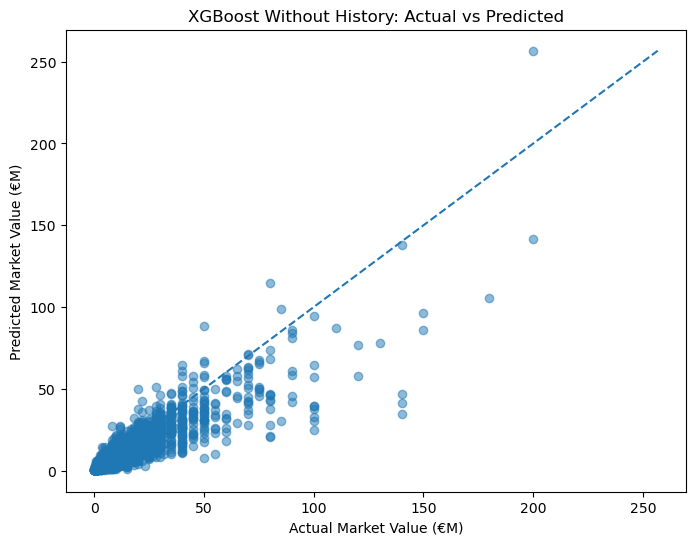

In [64]:
# plot actual vs predicted without history
plt.figure(figsize=(8, 6))

plt.scatter(
    test_analysis["target_market_value_in_eur"] / 1_000_000,
    test_analysis["pred_without_history_eur"] / 1_000_000,
    alpha=0.5
)

max_value = max(
    test_analysis["target_market_value_in_eur"].max(),
    test_analysis["pred_without_history_eur"].max()
) / 1_000_000

plt.plot(
    [0, max_value],
    [0, max_value],
    linestyle="--"
)

plt.xlabel("Actual Market Value (€M)")
plt.ylabel("Predicted Market Value (€M)")
plt.title("XGBoost Without History: Actual vs Predicted")

plt.show()

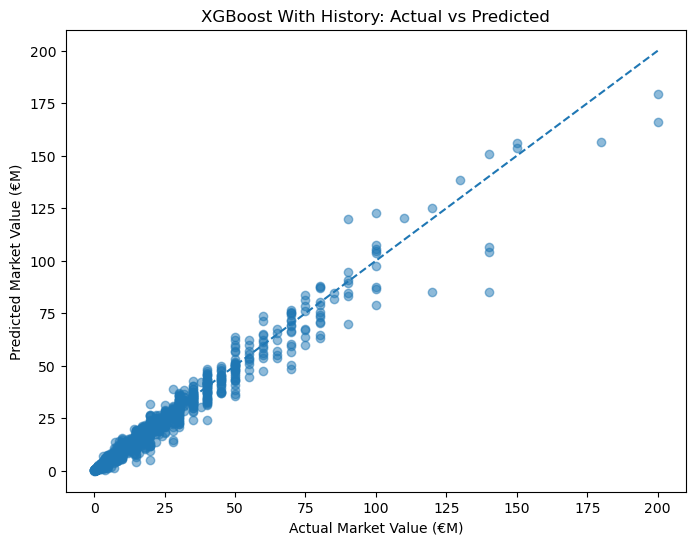

In [65]:
# plot actual vs predicted with history
plt.figure(figsize=(8, 6))

plt.scatter(
    test_analysis["target_market_value_in_eur"] / 1_000_000,
    test_analysis["pred_with_history_eur"] / 1_000_000,
    alpha=0.5
)

max_value = max(
    test_analysis["target_market_value_in_eur"].max(),
    test_analysis["pred_with_history_eur"].max()
) / 1_000_000

plt.plot(
    [0, max_value],
    [0, max_value],
    linestyle="--"
)

plt.xlabel("Actual Market Value (€M)")
plt.ylabel("Predicted Market Value (€M)")
plt.title("XGBoost With History: Actual vs Predicted")

plt.show()

The predicted vs actual plots reinforce the findings from the value-band analysis. 

The without-history model increasingly underestimates high-value players, while the with-history model remains substantially closer to observed valuations across the market. 

Prediction errors increase toward the upper end of the value distribution in both scenarios.

### 11. Model Explainability with SHAP

SHAP (SHapley Additive exPlanations) is a game theoretic approach to explain the output of any machine learning model. See: https://shap.readthedocs.io/en/latest/


##### Without History Model

In [66]:
# for SHAP we need to separate the different components of the models
# preprocessing part
preprocessor_without_history = (
    final_xgb_without_history
    .named_steps["preprocessor"]
)

# already fitted XGBoost part
xgb_model_without_history = (
    final_xgb_without_history
    .named_steps["model"]
)



In [67]:
# give SHAP the transform information on 2025 data
X_test_transformed = (
    preprocessor_without_history
    .transform(X_test_without_history)
)

# get feature names from columns created after preprocessing
feature_names_without_history = (
    preprocessor_without_history
    .get_feature_names_out()
)

# convert sparse output to a dense array for easier SHAP handling
if hasattr(X_test_transformed, "toarray"):
    X_test_transformed = X_test_transformed.toarray()

# create a df for SHAP to show real feature names
X_test_shap = pd.DataFrame(
    X_test_transformed,
    columns=feature_names_without_history,
    index=X_test_without_history.index
)

In [68]:
# ask SHAP to explain the XGBoost model
import shap

# instantiate TreeExplainer
explainer_without_history = shap.TreeExplainer(
    xgb_model_without_history
)

# check how each feature affected the final result
shap_values_without_history = (
    explainer_without_history(
        X_test_shap
    )
)

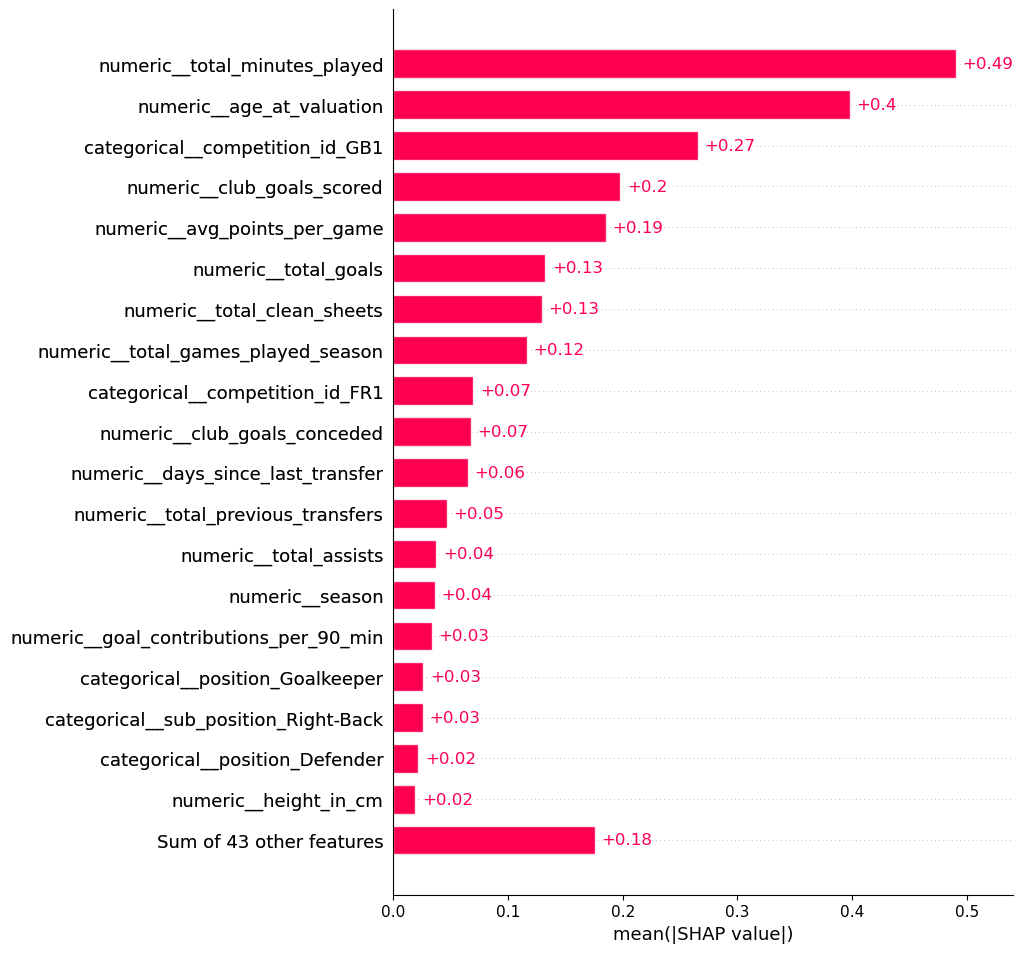

In [69]:
# plot the features that generally influence the predictions the most
# this plot is not showing the direction, just the absolute influence (positive does not mean is increasing the value)
shap.plots.bar(
    shap_values_without_history,
    max_display=20
)

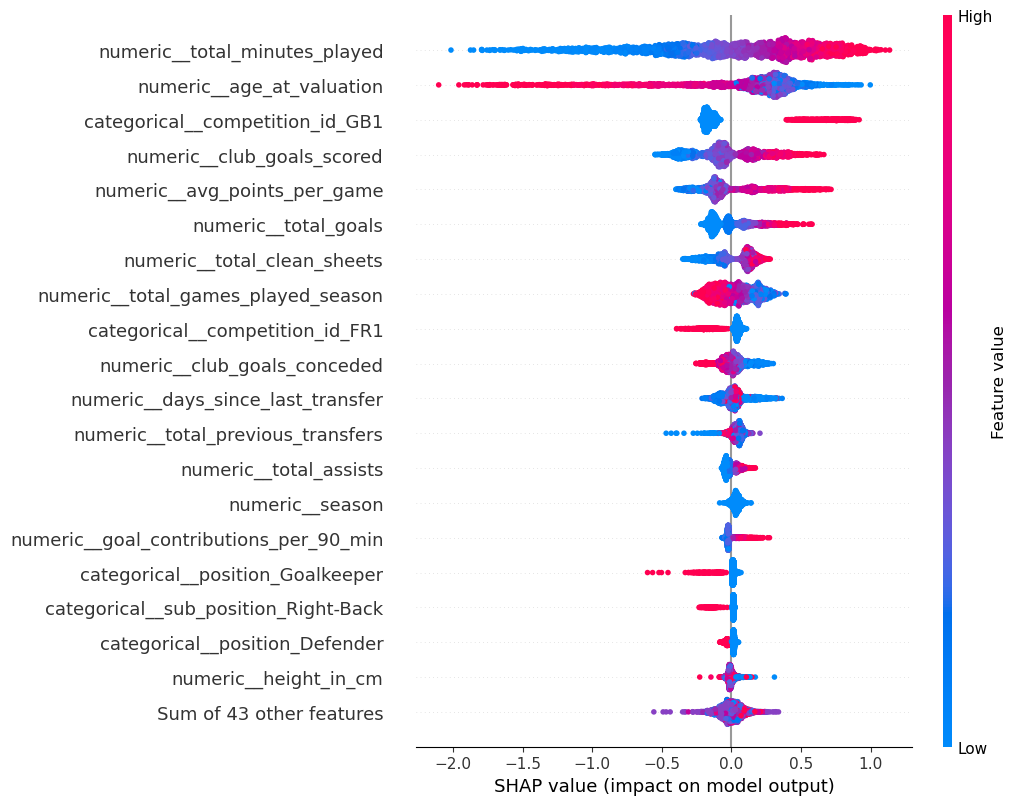

In [70]:
# plot the actual impact on model value of each feature
shap.plots.beeswarm(
    shap_values_without_history,
    max_display=20
)

SHAP analysis of the without-history model indicates that player valuation is driven primarily by playing time, age, competition, club performance and individual production. Total minutes played and age were the strongest predictors, while Premier League (England) participation and indicators of club strength also had substantial influence. 

Higher goals, assists and goal-contribution rates generally increased predicted value.

The results are consistent with the relationships identified during EDA and provide evidence that the model is learning interpretable football-market patterns rather than relying on isolated or unintuitive predictors. However, SHAP contributions represent associations learned by the model and should not be interpreted as causal effects. Some variables, particularly clean sheets and club-performance indicators, also capture broader team context rather than purely individual ability.

This model is also the more informative of the two from an explainability perspective, because valuation is derived from observable player and contextual characteristics rather than being dominated by an existing market valuation.

##### With History Model

In [71]:
# same procedure for model with previous market value

# preprocessing part
preprocessor_with_history = (
    final_xgb_with_history
    .named_steps["preprocessor"]
)


# already fitted XGBoost part
xgb_model_with_history = (
    final_xgb_with_history
    .named_steps["model"]
)

In [72]:
# give SHAP the transform information on 2025 data
X_test_with_history_transformed = (
    preprocessor_with_history
    .transform(X_test_with_history)
)

# get feature names from columns created after preprocessing
feature_names_with_history = (
    preprocessor_with_history
    .get_feature_names_out()
)

In [73]:
# convert sparse output to a dense array for easier SHAP handling
if hasattr(X_test_with_history_transformed,"toarray"):
    X_test_with_history_transformed = (
        X_test_with_history_transformed.toarray()
    )


# create a df for SHAP to show real feature names
X_test_shap_with_history = pd.DataFrame(
    X_test_with_history_transformed,
    columns=feature_names_with_history,
    index=X_test_with_history.index
)

In [74]:
# ask SHAP to explain the XGBoost model

# instantiate TreeExplainer
explainer_with_history = shap.TreeExplainer(
    xgb_model_with_history
)

# check how each feature affected the final result
shap_values_with_history = (
    explainer_with_history(
        X_test_shap_with_history
    )
)

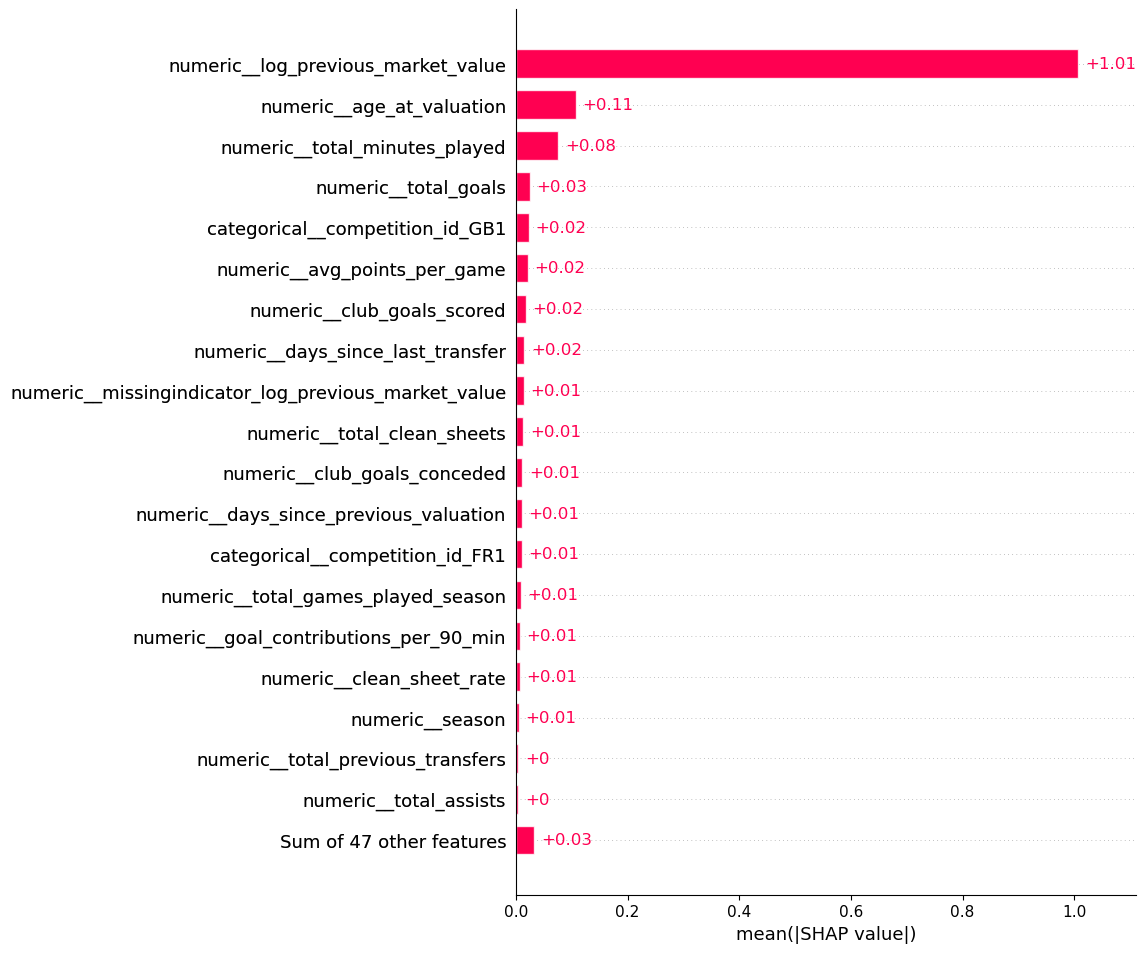

In [75]:
# plot the features that generally influence the predictions the most
# this plot is not showing the direction, just the absolute influence (positive does not mean is increasing the value)
shap.plots.bar(
    shap_values_with_history,
    max_display=20
)

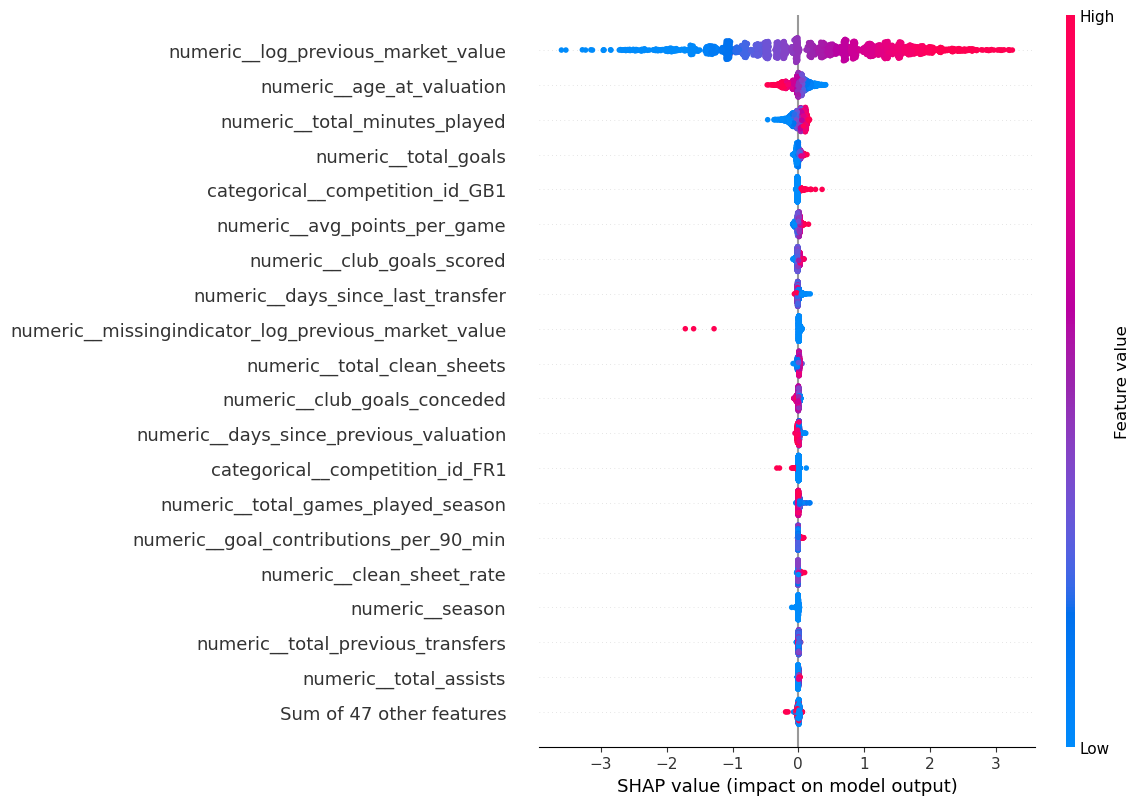

In [76]:
# plot the actual impact on model value of each feature
shap.plots.beeswarm(
    shap_values_with_history,
    max_display=20
)

SHAP analysis of the with-history XGBoost model shows that previous market value is overwhelmingly the most influential predictor, with substantially greater average impact than any player-performance or contextual feature. Higher historical valuations strongly increase predicted end-of-season value, while lower historical valuations reduce it.

Age and total minutes played remain the most important additional predictors, followed by goals and club/competition context, although their influence is considerably smaller. This supports the interpretation of the with-history model primarily as a market-value updating model: historical valuation establishes the player's approximate market level, while current-season characteristics and performance make incremental adjustments.

This result is consistent with the strong persistence observed during EDA and with the performance of the persistence baseline. It also helps explain why sudden large repricing events remain difficult for the model to predict.

##### Individual SHAP Comparison

Lets compare now the SHAP comparisons for the best and worst predicted players across the two models.

AI-assisted implementation note: ChatGPT was used to generate and refine the Python code for the individual SHAP comparison between the best- and worst-predicted players under both model scenarios. The generated code was reviewed and adapted before inclusion in the analysis (OpenAI, 2026).

In [77]:
# compact comparison table in €M
player_comparison = test_analysis.assign(
    actual_m=test_analysis["target_market_value_in_eur"] / 1_000_000,
    pred_without_m=test_analysis["pred_without_history_eur"] / 1_000_000,
    pred_with_m=test_analysis["pred_with_history_eur"] / 1_000_000,
    error_without_m=test_analysis["error_without_history_eur"] / 1_000_000,
    error_with_m=test_analysis["error_with_history_eur"] / 1_000_000
)[
    [
        "player_id",
        "name",
        "position",
        "actual_m",
        "pred_without_m",
        "error_without_m",
        "pred_with_m",
        "error_with_m"
    ]
]

# create general mean error column
player_comparison["mean_error_m"] = (
    player_comparison["error_without_m"]
    + player_comparison["error_with_m"]
) / 2

In [78]:
# select the best and worst prediction
best_player = (
    player_comparison
    .nsmallest(1, "mean_error_m")
    .assign(selection="Best overall prediction")
)

worst_player = (
    player_comparison
    .nlargest(1, "mean_error_m")
    .assign(selection="Worst overall prediction")
)

selected_players = pd.concat([
    best_player,
    worst_player
])

selected_players[
    [
        "selection",
        "name",
        "position",
        "actual_m",
        "pred_without_m",
        "error_without_m",
        "pred_with_m",
        "error_with_m",
        "mean_error_m"
    ]
]

,selection,name,position,actual_m,pred_without_m,error_without_m,pred_with_m,error_with_m,mean_error_m
13195,Best overall prediction,Patrik Carlgren,Goalkeeper,0.4,0.397896,0.002104,0.395147,0.004853,0.003479
14161,Worst overall prediction,Khvicha Kvaratskhelia,Attack,140.0,41.569736,98.430264,85.039871,54.960128,76.695196


In [79]:

def explain_player(player_id, model="without_history", max_display=12):

    # Original row index
    idx = test_analysis[
        test_analysis["player_id"] == player_id
    ].index[0]

    if model == "without_history":

        shap_position = X_test_without_history.index.get_loc(idx)
        shap_values = shap_values_without_history

        actual = (
            test_analysis.loc[idx, "target_market_value_in_eur"]
            / 1_000_000
        )

        predicted = (
            test_analysis.loc[idx, "pred_without_history_eur"]
            / 1_000_000
        )

        label = "Without History"

    else:

        shap_position = X_test_with_history.index.get_loc(idx)
        shap_values = shap_values_with_history

        actual = (
            test_analysis.loc[idx, "target_market_value_in_eur"]
            / 1_000_000
        )

        predicted = (
            test_analysis.loc[idx, "pred_with_history_eur"]
            / 1_000_000
        )

        label = "With History"

    name = test_analysis.loc[idx, "name"]

    print(f"{name} — {label}")
    print(f"Actual:    €{actual:.1f}M")
    print(f"Predicted: €{predicted:.1f}M")
    print(f"Error:     €{abs(actual - predicted):.1f}M")

    shap.plots.waterfall(
        shap_values[shap_position],
        max_display=max_display
    )

Patrik Carlgren — Without History
Actual:    €0.4M
Predicted: €0.4M
Error:     €0.0M


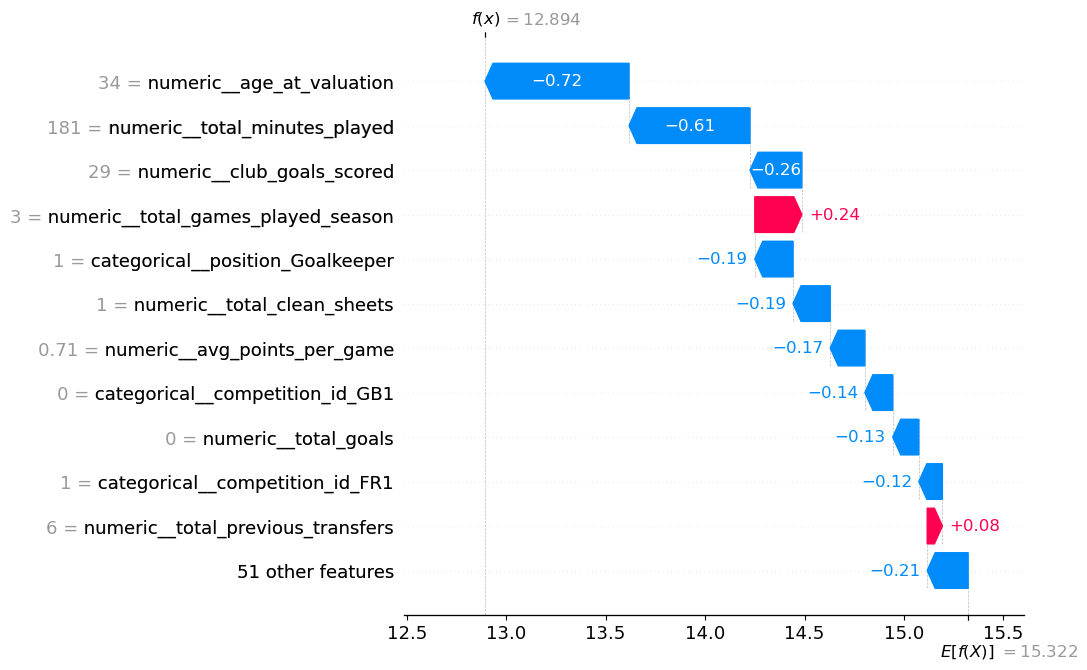

Patrik Carlgren — With History
Actual:    €0.4M
Predicted: €0.4M
Error:     €0.0M


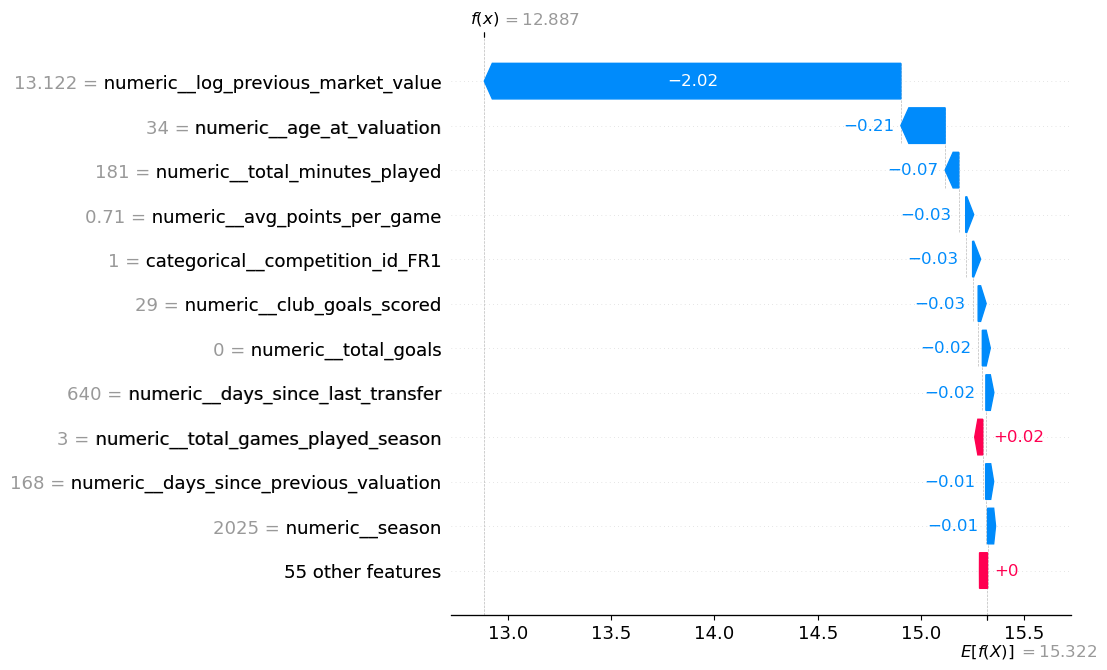

Khvicha Kvaratskhelia — Without History
Actual:    €140.0M
Predicted: €41.6M
Error:     €98.4M


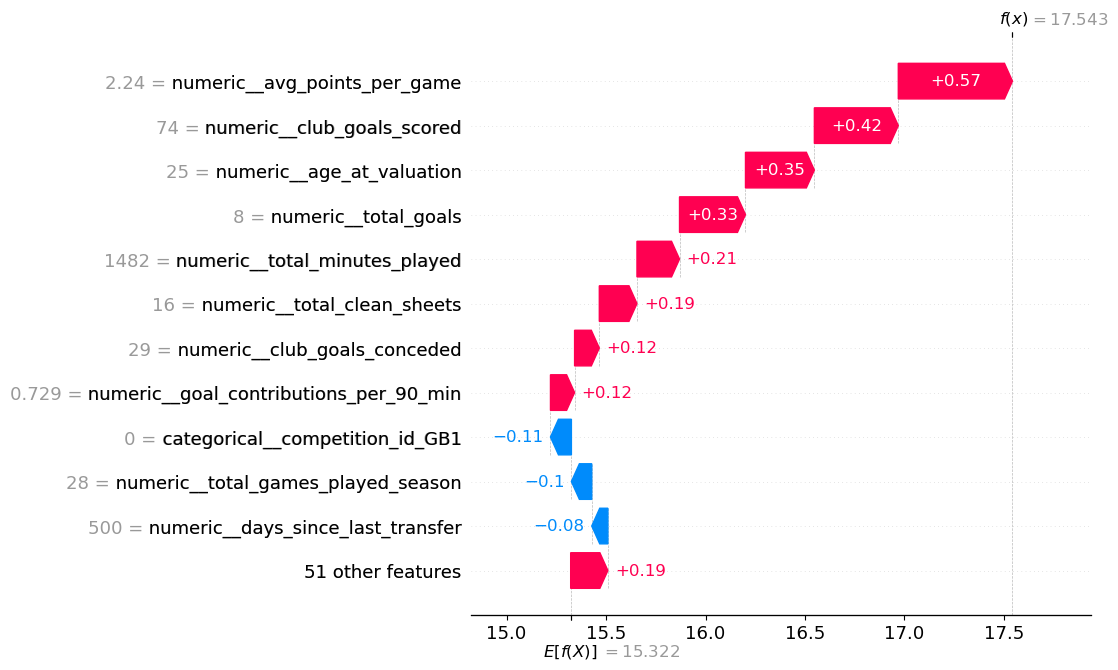

Khvicha Kvaratskhelia — With History
Actual:    €140.0M
Predicted: €85.0M
Error:     €55.0M


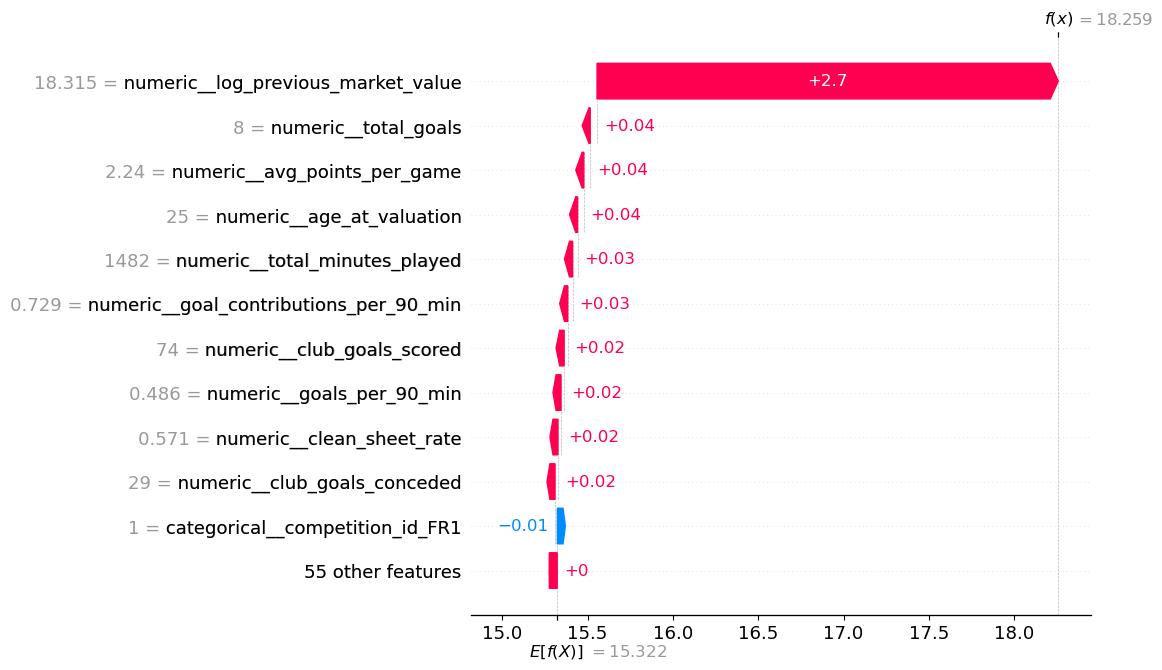

In [80]:
for player_id in selected_players["player_id"].unique():

    explain_player(
        player_id,
        model="without_history"
    )

    explain_player(
        player_id,
        model="with_history"
    )

Individual SHAP explanations confirm the different roles of the two models: 

- The without-history model builds valuations mainly from age, playing time, competition, player performance, and club context, but struggles with extreme high-value cases. 

- The with-history model is strongly anchored by the previous market valuation, while current-season features make smaller adjustments. This improves accuracy substantially, although large market repricing events can still be underestimated.

### 12. Conclusions

XGBoost provided the strongest performance in both modeling scenarios. The without-history model achieved an MAE of €4.75M and R² of 0.74 on the 2025 test season, showing that player, performance and contextual features contain substantial information about market value. Including historical valuation reduced MAE to €1.46M and increased R² to 0.97, although the persistence baseline and SHAP analysis show that previous market value accounts for most of this predictive power.

Error analysis identified high-value players and large repricing events as the main limitations of the current models. 

Future iterations could therefore focus on:

1. Richer performance, competition and club-context features (more features).
2. Expansion to other competitions and seasons (more data).

### 13. Model Storing

In [81]:
# store both models using joblib

import joblib
from pathlib import Path

Path("../models").mkdir(exist_ok=True)

joblib.dump(
    final_xgb_without_history,
    "../models/xgb_without_history.joblib"
)

joblib.dump(
    final_xgb_with_history,
    "../models/xgb_with_history.joblib"
)

['../models/xgb_with_history.joblib']

#### Save Model Metadata

In [82]:
import json

model_metadata = {
    "target": "log_target_market_value",
    "training_seasons": "2020-2024",
    "test_season": 2025,

    "without_history_features": features_without_history,
    "with_history_features": features_with_history,

    "best_params_without_history": grid_without_history.best_params_,
    "best_params_with_history": grid_with_history.best_params_,

    "test_mae_without_history_m": test_mae_without_history / 1_000_000,
    "test_rmse_without_history_m": test_rmse_without_history / 1_000_000,
    "test_r2_without_history": test_r2_without_history,

    "test_mae_with_history_m": test_mae_with_history / 1_000_000,
    "test_rmse_with_history_m": test_rmse_with_history / 1_000_000,
    "test_r2_with_history": test_r2_with_history
}

with open(
    "../models/model_metadata.json",
    "w"
) as f:
    json.dump(
        model_metadata,
        f,
        indent=4
    )